# Synthetic Data Generation using TabFairGAN

This notebook implements a TabFairGAN (Tabular Fair GAN) model to generate synthetic data.

The objective is to compare TabFairGAN with non-fair models in terms of:
- Data quality
- Preservation of statistical properties
- Fairness across sensitive attributes

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tabfairgan import TFG

/Users/staceykagio/fair-synthetic-data-gen/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Dataset

We use the Adult Income dataset which is our test data.

In [2]:
df = pd.read_csv("test_data/adult.csv")

df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## Data Preprocessing

We define categorical variables and clean the dataset.

In [3]:
df = df.dropna()

categorical_columns = [
    'workclass', 'education', 'marital-status',
    'occupation', 'relationship', 'race',
    'sex', 'native-country', 'income'
]

## TabFairGAN Model Training

TabFairGAN differs from standard generative models such as CTGAN in that fairness constraints are incorporated directly into the training process.

Instead of using a separate fit function, the model is trained using a custom training loop.

### Fairness Constraint
To generate fair synthetic data, you need to pass a dictionary containing the following parameters:

- fair_epochs: Number of fair training epochs (integer).
- lamda: Lambda parameter controlling the trade-off between fairness and accuracy (float).
- S: Protected attribute (string, e.g., "sex").
- Y: Decision label (string, e.g., "income").
- S_under: Value representing the underprivileged group for the protected attribute (string, e.g., " Female").
- Y_desire: Desired value for the label (string, e.g., " >50K").

In [6]:
# Define fairness configuration
fairness_config = {
    'fair_epochs': 50,
    'lamda': 0.5,
    'S': 'sex',
    'Y': 'income',
    'S_under': ' Female',
    'Y_desire': ' >50K'
}

# Initialize TabFairGAN with fairness constraints
model = TFG(
    df, 
    epochs=200, 
    batch_size=256, 
    fairness_config=fairness_config
)

# Train the model
model.train()

Training Progress:   0%|                             | 0/200 [00:00<?, ?it/s, Training for accuracy]

epoch 1


Training Progress:   0%|                     | 1/200 [00:12<40:14, 12.13s/it, Training for accuracy]

epoch 2


Training Progress:   1%|▏                    | 2/200 [00:30<51:55, 15.74s/it, Training for accuracy]

...

Training Progress:  99%|████████████████▊| 198/200 [1:10:14<00:59, 29.77s/it, Training for fairness]

epoch 199


Training Progress: 100%|████████████████▉| 199/200 [1:10:50<00:31, 31.49s/it, Training for fairness]

epoch 200


Training Progress: 100%|█████████████████| 200/200 [1:11:35<00:00, 21.48s/it, Training for fairness]


## Synthetic Data Generation

In [8]:
synthetic_data = model.generate_fake_df(num_rows=5000)

synthetic_data.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,25.0,Private,1.679810e+05,Assoc-voc,11.0,Never-married,Tech-support,Not-in-family,White,Male,0.0,0.0,40.0,United-States,<=50K
1,52.0,?,1.246734e+05,Some-college,9.0,Divorced,?,Own-child,White,Female,0.0,0.0,40.0,United-States,<=50K
2,20.0,Private,1.490400e+06,11th,6.0,Never-married,Sales,Own-child,White,Male,0.0,0.0,1.0,United-States,<=50K
3,48.0,Private,2.009971e+05,10th,1.0,Widowed,Sales,Unmarried,White,Female,0.0,0.0,40.0,United-States,<=50K
4,42.0,Private,1.803882e+05,Assoc-acdm,13.0,Married-civ-spouse,Craft-repair,Husband,White,Male,0.0,0.0,50.0,United-States,>50K


## Distribution Comparison

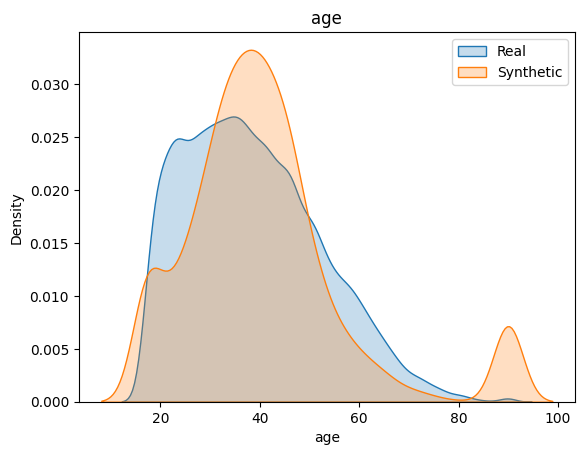

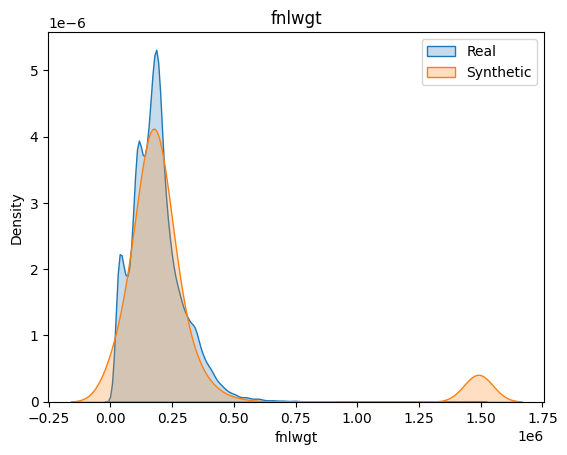

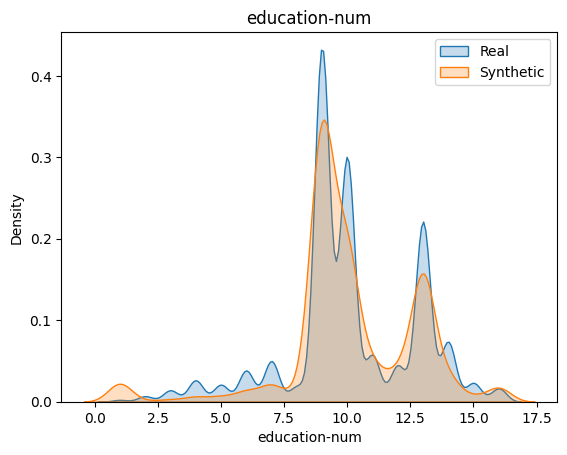

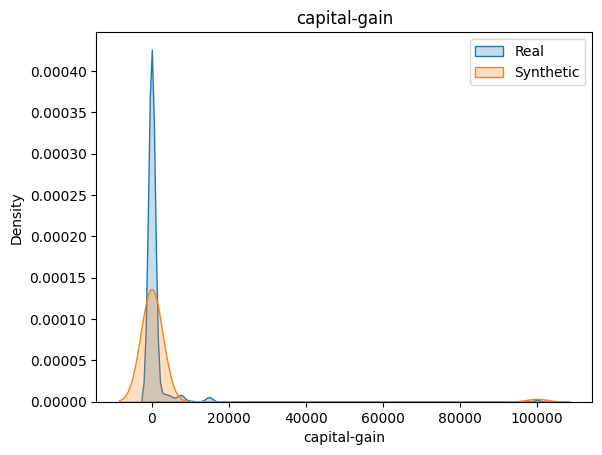

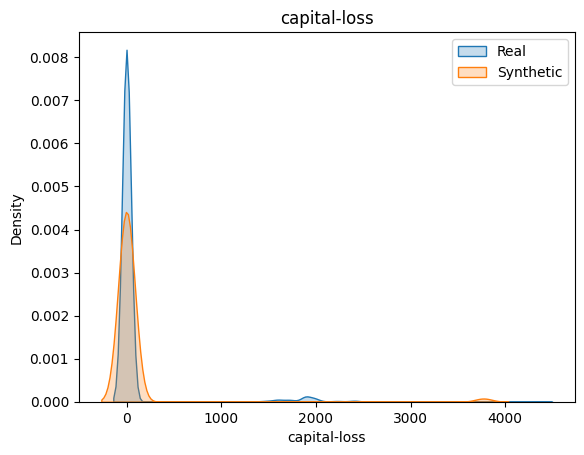

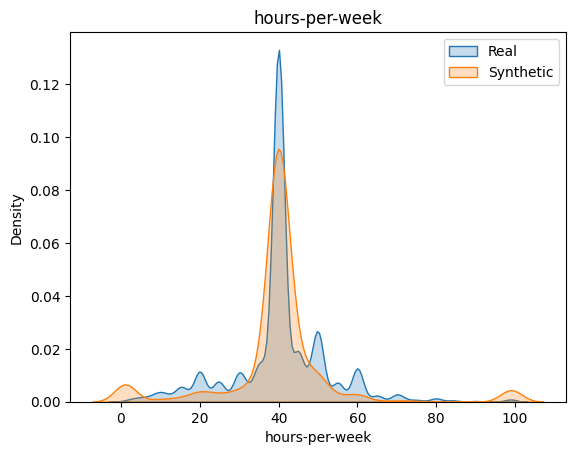

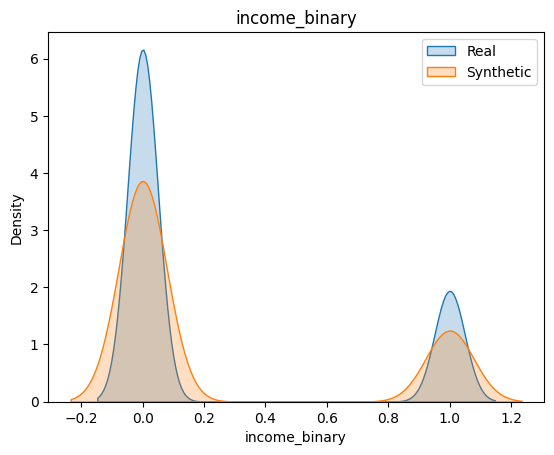

In [15]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in numerical_cols:
    plt.figure()
    sns.kdeplot(df[col], label="Real", fill=True)
    sns.kdeplot(synthetic_data[col], label="Synthetic", fill=True)
    plt.title(col)
    plt.legend()
    plt.show()

## Fairness Evaluation

In [10]:
#Convert income to binary
df['income_binary'] = df['income'].apply(lambda x: 1 if '>50K' in x else 0)
synthetic_data['income_binary'] = synthetic_data['income'].apply(lambda x: 1 if '>50K' in x else 0)

In [11]:
#Statistical Parity
real_sp = df.groupby('sex')['income_binary'].mean()
syn_sp = synthetic_data.groupby('sex')['income_binary'].mean()

print("Real:")
print(real_sp)

print("\nSynthetic:")
print(syn_sp)

Real:
sex
Female    0.109251
Male      0.303767
Name: income_binary, dtype: float64

Synthetic:
sex
Female    0.219676
Male      0.256929
Name: income_binary, dtype: float64


In [12]:
#Disparity Gap
real_sp = df.groupby('sex')['income_binary'].mean()
syn_sp = synthetic_data.groupby('sex')['income_binary'].mean()

print("Real:")
print(real_sp)

print("\nSynthetic:")
print(syn_sp)

Real:
sex
Female    0.109251
Male      0.303767
Name: income_binary, dtype: float64

Synthetic:
sex
Female    0.219676
Male      0.256929
Name: income_binary, dtype: float64
